# Animal Crossing Fish Analysis

This notebook explores and visualizes fish data from Animal Crossing: New Horizons.

## Import Required Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set style for better-looking plots
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

## Load the Fish Dataset

In [2]:
# Load the fish data
fish_df = pd.read_csv('../data/acnh-data/fish.csv')

# Display basic information
print(f"Dataset shape: {fish_df.shape}")
print(f"\nColumn names:")
print(fish_df.columns.tolist())

Dataset shape: (80, 41)

Column names:
['#', 'Name', 'Sell', 'Where/How', 'Shadow', 'Total Catches to Unlock', 'Spawn Rates', 'Rain/Snow Catch Up', 'NH Jan', 'NH Feb', 'NH Mar', 'NH Apr', 'NH May', 'NH Jun', 'NH Jul', 'NH Aug', 'NH Sep', 'NH Oct', 'NH Nov', 'NH Dec', 'SH Jan', 'SH Feb', 'SH Mar', 'SH Apr', 'SH May', 'SH Jun', 'SH Jul', 'SH Aug', 'SH Sep', 'SH Oct', 'SH Nov', 'SH Dec', 'Color 1', 'Color 2', 'Size', 'Lighting Type', 'Icon Filename', 'Critterpedia Filename', 'Furniture Filename', 'Internal ID', 'Unique Entry ID']


## Explore the Data

In [3]:
# Display first few rows
fish_df.head(10)

,#,Name,Sell,Where/How,Shadow,Total Catches to Unlock,Spawn Rates,Rain/Snow Catch Up,NH Jan,NH Feb,...,SH Dec,Color 1,Color 2,Size,Lighting Type,Icon Filename,Critterpedia Filename,Furniture Filename,Internal ID,Unique Entry ID
0,56,anchovy,200,Sea,Small,0,2–5,No,4 AM – 9 PM,4 AM – 9 PM,...,4 AM – 9 PM,Blue,Red,1x1,No lighting,Fish81,FishAntyobi,FtrFishAntyobi,4201,LzuWkSQP55uEpRCP5
1,36,angelfish,3000,River,Small,20,2–5,No,NaN,NaN,...,4 PM – 9 AM,Yellow,Black,1x1,Fluorescent,Fish30,FishAngelfish,FtrFishAngelfish,2247,XTCFCk2SiuY5YXLZ7
2,44,arapaima,10000,River,XX-Large,50,1,Yes,NaN,NaN,...,4 PM – 9 AM,Black,Blue,3x2,No lighting,Fish36,FishPiraruku,FtrFishPiraruku,2253,mZy4BES54bqwi97br
3,41,arowana,10000,River,Large,50,1–2,No,NaN,NaN,...,4 PM – 9 AM,Yellow,Black,2x1,Fluorescent,Fish33,FishArowana,FtrFishArowana,2250,F68AvCaqddBJL7ZSN
4,58,barred knifejaw,5000,Sea,Medium,20,3–5,No,NaN,NaN,...,All day,White,Black,1x1,Fluorescent,Fish47,FishIshidai,FtrFishIshidai,2265,X3R9SFSAaDzBF4fE3
5,79,barreleye,15000,Sea,Small,100,1,No,9 PM – 4 AM,9 PM – 4 AM,...,9 PM – 4 AM,Black,Black,1x1,Fluorescent,Fish84,FishDemenigisu,FtrFishDemenigisu,4204,BpqTa4zmTjv3Nm4wE
6,37,betta,2500,River,Small,20,1–4,No,NaN,NaN,...,9 AM – 4 PM,Light blue,Black,1x1,Fluorescent,Fish77,FishBeta,FtrFishBeta,4191,7QcQXzwZoNGiNA94k
7,1,bitterling,900,River,X-Small,0,12–17,No,All day,All day,...,NaN,Light blue,Blue,1x1,No lighting,Fish0,FishTanago,FtrFishTanago,2215,Drj6eLRBgg4T9KhNx
8,22,black bass,400,River,Large,0,4–12,No,All day,All day,...,All day,Green,Black,1x1,Fluorescent,Fish19,FishBlackbass,FtrFishBlackbass,2234,wAZvfTca7GyaTtLcQ
9,54,blowfish,5000,Sea,Medium,20,5,No,9 PM – 4 AM,9 PM – 4 AM,...,NaN,Beige,Black,1x1,Fluorescent,Fish73,FishFugu,FtrFishFugu,2262,aDsmTcByApycafxTa


In [4]:
# Check data types and missing values
fish_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 41 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   #                        80 non-null     int64 
 1   Name                     80 non-null     object
 2   Sell                     80 non-null     int64 
 3   Where/How                80 non-null     object
 4   Shadow                   80 non-null     object
 5   Total Catches to Unlock  80 non-null     int64 
 6   Spawn Rates              80 non-null     object
 7   Rain/Snow Catch Up       80 non-null     object
 8   NH Jan                   31 non-null     object
 9   NH Feb                   31 non-null     object
 10  NH Mar                   35 non-null     object
 11  NH Apr                   39 non-null     object
 12  NH May                   44 non-null     object
 13  NH Jun                   55 non-null     object
 14  NH Jul                   58 non-null     obj

In [5]:
# Statistical summary
fish_df.describe()

,#,Sell,Total Catches to Unlock,Internal ID
count,80.0000,80.000000,80.000000,80.000000
mean,40.5000,3745.000000,19.250000,2483.087500
std,23.2379,4517.151561,27.364164,795.196102
min,1.0000,100.000000,0.000000,328.000000
25%,20.7500,500.000000,0.000000,2234.750000
50%,40.5000,1500.000000,0.000000,2255.500000
75%,60.2500,5000.000000,20.000000,2275.250000
max,80.0000,15000.000000,100.000000,5254.000000


## Data Cleaning and Preparation

In [6]:
# Check for missing values
missing_values = fish_df.isnull().sum()
print("Missing values per column:")
print(missing_values[missing_values > 0])

Missing values per column:
NH Jan    49
NH Feb    49
NH Mar    45
NH Apr    41
NH May    36
NH Jun    25
NH Jul    22
NH Aug    20
NH Sep    17
NH Oct    38
NH Nov    43
NH Dec    48
SH Jan    22
SH Feb    20
SH Mar    17
SH Apr    38
SH May    43
SH Jun    48
SH Jul    49
SH Aug    49
SH Sep    45
SH Oct    41
SH Nov    36
SH Dec    25
dtype: int64


## Visualizations

### Price Distribution

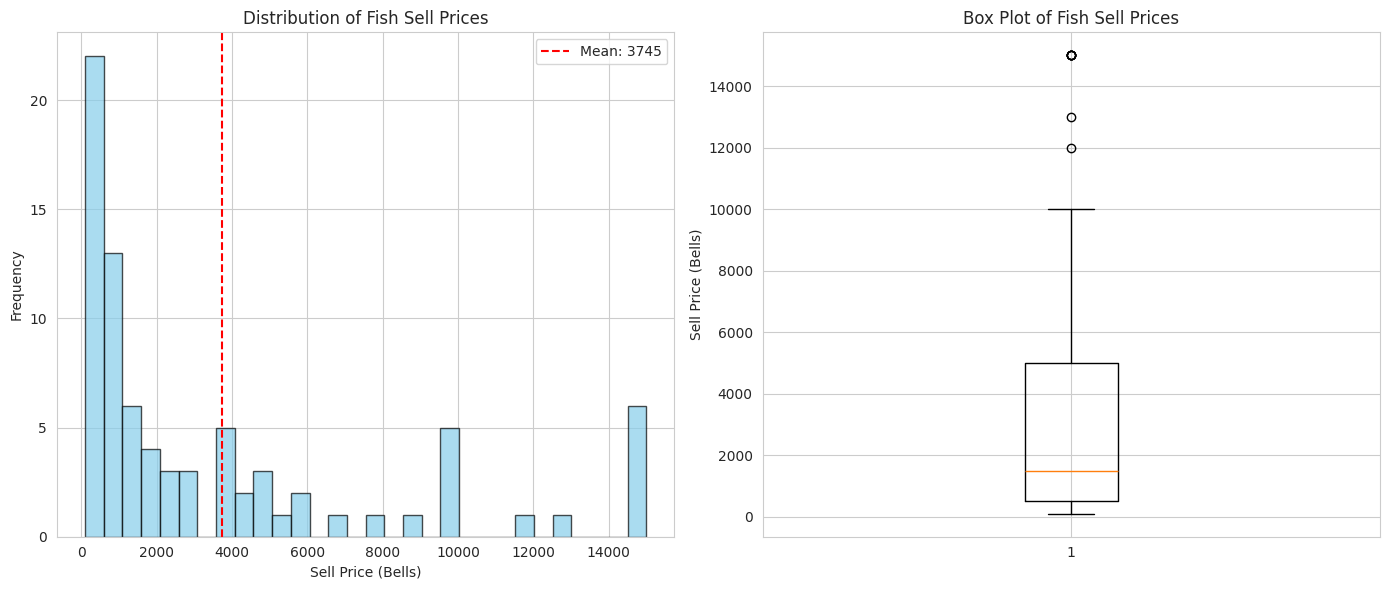

In [7]:
# Visualize fish sell prices
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.hist(fish_df['Sell'], bins=30, edgecolor='black', alpha=0.7, color='skyblue')
plt.xlabel('Sell Price (Bells)')
plt.ylabel('Frequency')
plt.title('Distribution of Fish Sell Prices')
plt.axvline(fish_df['Sell'].mean(), color='red', linestyle='--', label=f'Mean: {fish_df["Sell"].mean():.0f}')
plt.legend()

plt.subplot(1, 2, 2)
plt.boxplot(fish_df['Sell'], vert=True)
plt.ylabel('Sell Price (Bells)')
plt.title('Box Plot of Fish Sell Prices')

plt.tight_layout()
plt.show()

### Top 10 Most Valuable Fish

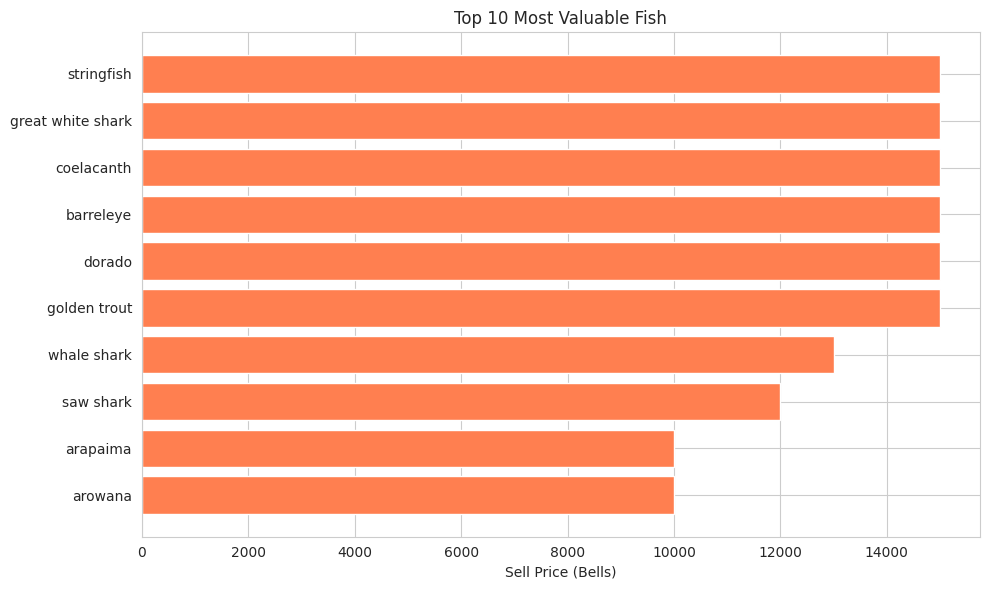


Top 10 Most Valuable Fish:
                 Name   Sell       Shadow         Where/How
5           barreleye  15000        Small               Sea
18         coelacanth  15000     XX-Large  Sea (rainy days)
23             dorado  15000      X-Large             River
30       golden trout  15000       Medium  River (clifftop)
32  great white shark  15000  Large w/Fin               Sea
69         stringfish  15000      X-Large  River (clifftop)
77        whale shark  13000  Large w/Fin               Sea
62          saw shark  12000  Large w/Fin               Sea
2            arapaima  10000     XX-Large             River
3             arowana  10000        Large             River


In [8]:
# Top 10 most valuable fish
top_10_fish = fish_df.nlargest(10, 'Sell')[['Name', 'Sell']].sort_values('Sell', ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(top_10_fish['Name'], top_10_fish['Sell'], color='coral')
plt.xlabel('Sell Price (Bells)')
plt.title('Top 10 Most Valuable Fish')
plt.tight_layout()
plt.show()

print("\nTop 10 Most Valuable Fish:")
print(fish_df.nlargest(10, 'Sell')[['Name', 'Sell', 'Shadow', 'Where/How']])

### Fish by Shadow Size

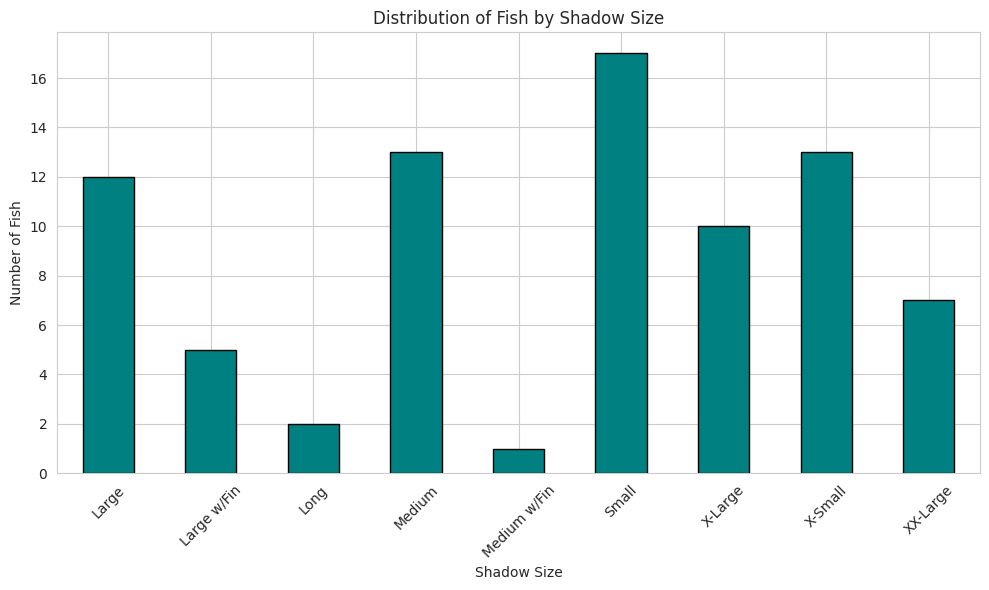

In [9]:
# Fish count by shadow size
shadow_counts = fish_df['Shadow'].value_counts().sort_index()

plt.figure(figsize=(10, 6))
shadow_counts.plot(kind='bar', color='teal', edgecolor='black')
plt.xlabel('Shadow Size')
plt.ylabel('Number of Fish')
plt.title('Distribution of Fish by Shadow Size')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Fish Location Analysis

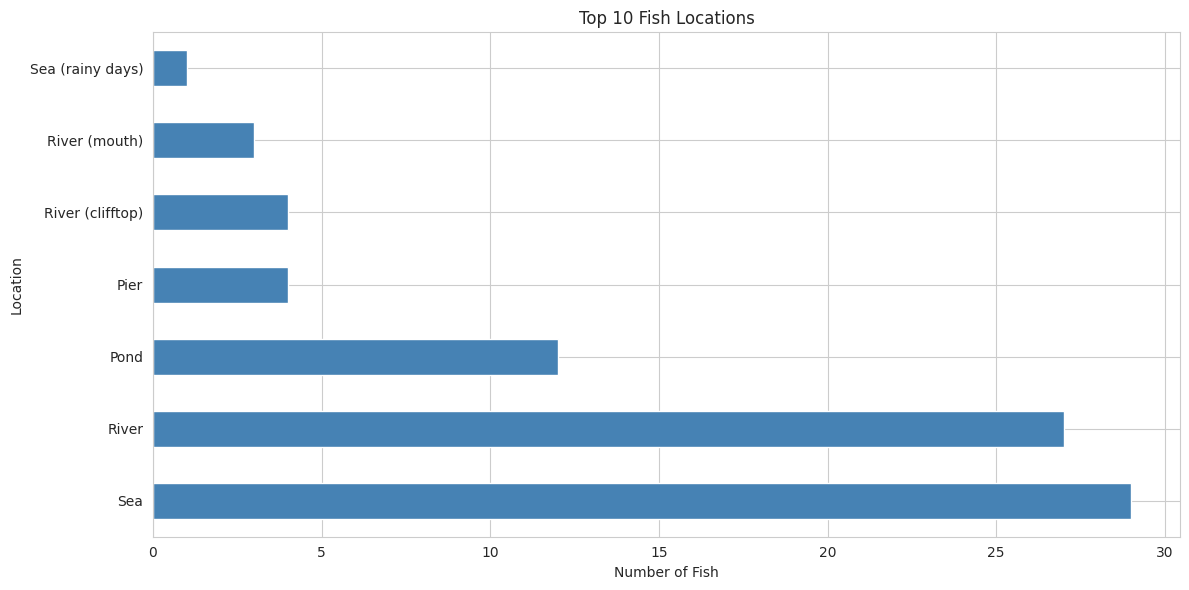

In [10]:
# Fish by location
location_counts = fish_df['Where/How'].value_counts().head(10)

plt.figure(figsize=(12, 6))
location_counts.plot(kind='barh', color='steelblue')
plt.xlabel('Number of Fish')
plt.ylabel('Location')
plt.title('Top 10 Fish Locations')
plt.tight_layout()
plt.show()

### Monthly Availability

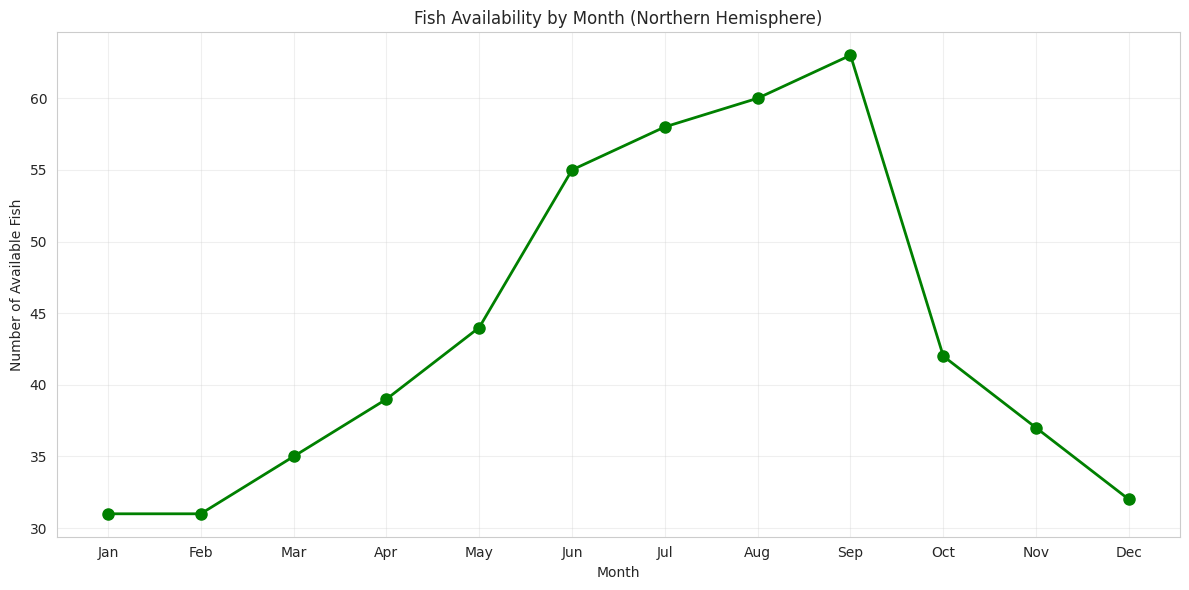

In [12]:
# Analyze monthly availability (Northern Hemisphere)
nh_months = ['NH Jan', 'NH Feb', 'NH Mar', 'NH Apr', 'NH May', 'NH Jun',
             'NH Jul', 'NH Aug', 'NH Sep', 'NH Oct', 'NH Nov', 'NH Dec']

if all(col in fish_df.columns for col in nh_months):
    # Count non-NA values (fish available) for each month
    monthly_availability = fish_df[nh_months].notna().sum().values
    month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
    
    plt.figure(figsize=(12, 6))
    plt.plot(month_names, monthly_availability, marker='o', linewidth=2, markersize=8, color='green')
    plt.xlabel('Month')
    plt.ylabel('Number of Available Fish')
    plt.title('Fish Availability by Month (Northern Hemisphere)')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

### Shadow Size vs. Price Relationship

/tmp/ipykernel_12265/2994932535.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=fish_df, x='Shadow', y='Sell', palette='Set2')


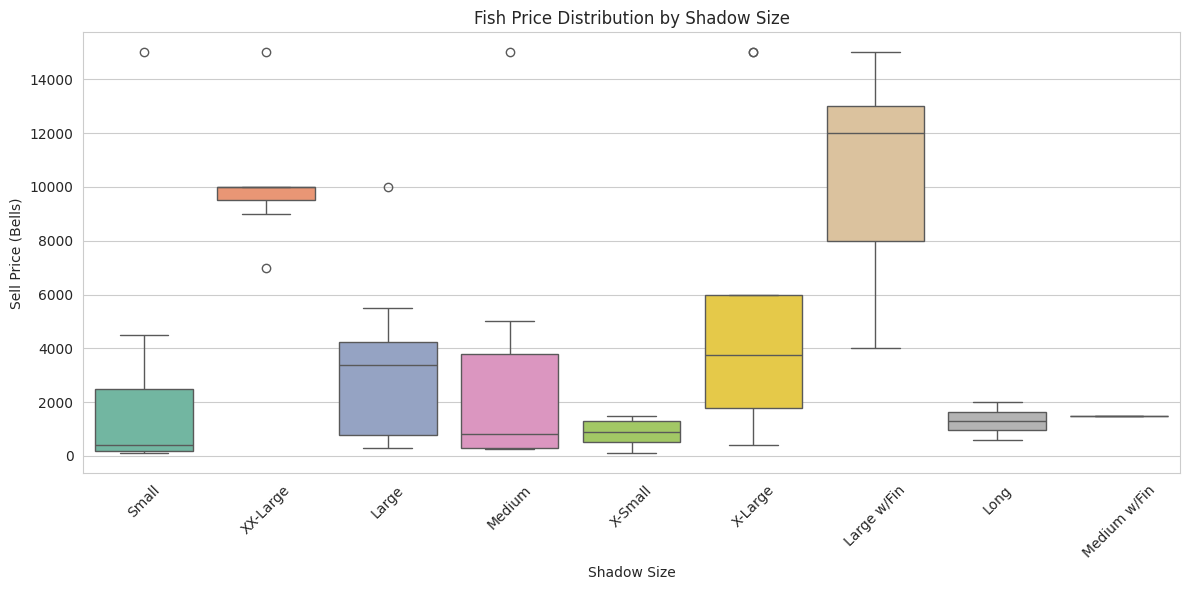


Average Price by Shadow Size:
                      mean   median  count
Shadow                                    
Large w/Fin   10400.000000  12000.0      5
XX-Large      10142.857143  10000.0      7
X-Large        5430.000000   3750.0     10
Large          3329.166667   3375.0     12
Medium         2583.846154    800.0     13
Small          1982.941176    400.0     17
Medium w/Fin   1500.000000   1500.0      1
Long           1300.000000   1300.0      2
X-Small         842.307692    900.0     13


In [13]:
# Relationship between shadow size and price
plt.figure(figsize=(12, 6))
sns.boxplot(data=fish_df, x='Shadow', y='Sell', palette='Set2')
plt.xlabel('Shadow Size')
plt.ylabel('Sell Price (Bells)')
plt.title('Fish Price Distribution by Shadow Size')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Calculate average price by shadow size
print("\nAverage Price by Shadow Size:")
print(fish_df.groupby('Shadow')['Sell'].agg(['mean', 'median', 'count']).sort_values('mean', ascending=False))

## Summary Statistics

In [14]:
# Summary statistics
print("=" * 50)
print("FISH DATASET SUMMARY")
print("=" * 50)
print(f"Total number of fish species: {len(fish_df)}")
print(f"\nPrice Statistics:")
print(f"  - Average sell price: {fish_df['Sell'].mean():.2f} Bells")
print(f"  - Median sell price: {fish_df['Sell'].median():.2f} Bells")
print(f"  - Min sell price: {fish_df['Sell'].min()} Bells")
print(f"  - Max sell price: {fish_df['Sell'].max()} Bells")
print(f"\nMost expensive fish: {fish_df.loc[fish_df['Sell'].idxmax(), 'Name']}")
print(f"Least expensive fish: {fish_df.loc[fish_df['Sell'].idxmin(), 'Name']}")
print("=" * 50)

FISH DATASET SUMMARY
Total number of fish species: 80

Price Statistics:
  - Average sell price: 3745.00 Bells
  - Median sell price: 1500.00 Bells
  - Min sell price: 100 Bells
  - Max sell price: 15000 Bells

Most expensive fish: barreleye
Least expensive fish: tadpole
